Аппроксимация функции $x^2$

$x \in (10^{-15}, 1]$

Для начала пошагово повторю пример из лекции

In [6]:
import math

import numpy as np
import torch
from data import get_data
from matplotlib import pyplot as plt
from models import MLP, MLP3
from torch import nn, optim
from train import run

x_train, y_train, x_val, y_val = get_data()
torch.manual_seed(42)

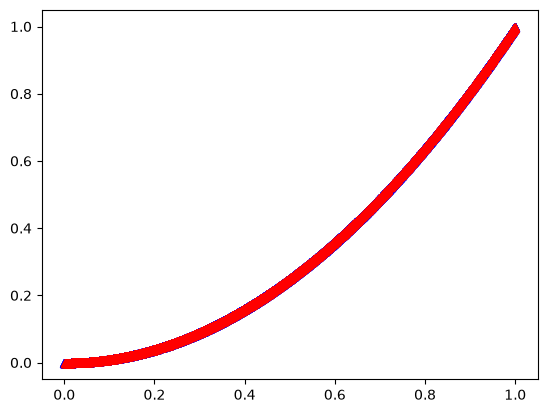

In [7]:
plt.figure("train")
plt.plot(x_train.numpy(), y_train.numpy(), "b", lw=0, marker="^")
plt.plot(x_val.numpy(), y_val.numpy(), "r", lw=0, marker="^")
plt.show()


- 2 слоя: 1 –50 –1
- Relu
- batch=128
- epoch=200
- Adam (lr=0.001)
- без изменения lr
- Loss: MSE

MSE: 9.603830221749377e-06, MAPE: 3.6561503410339355


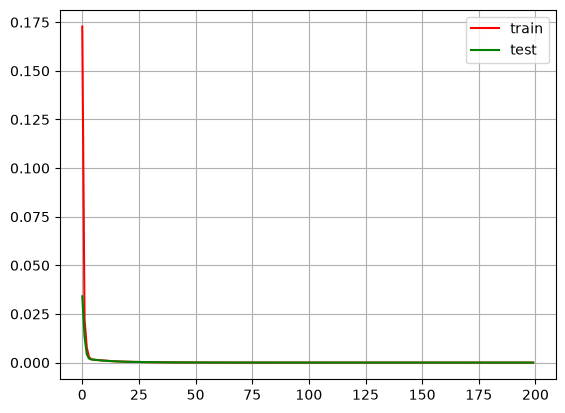

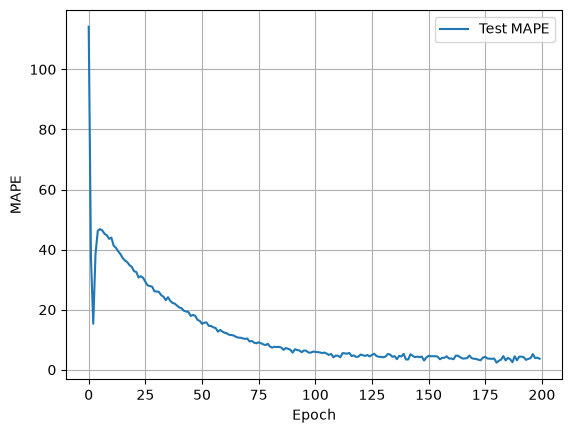

In [8]:
model = MLP()
batch_size = 128
n_epoch = 200
lr = 0.001

# Defines a optimizer to update the parameters
optimizer = optim.Adam(model.parameters(), lr=lr)
model_loss = nn.MSELoss()

train_errors, test_errors, test_mapes = run(model, model_loss, optimizer, x_train, y_train, x_val, y_val, n_epoch, batch_size)

print(f"MSE: {test_errors[-1][1]}, MAPE: {test_mapes[-1][1]}")

plt.figure("Errors")
train_errors = np.array(train_errors)
test_errors = np.array(test_errors)
plt.plot(train_errors[:,0],train_errors[:,1],"r-",label = "train")
plt.plot(test_errors[:,0],test_errors[:,1],"g-",label = "test")
plt.legend()
plt.grid()
plt.show()

test_mapes = np.array(test_mapes)
plt.plot(test_mapes[:,0], test_mapes[:,1], label="Test MAPE")
plt.xlabel("Epoch")
plt.ylabel("MAPE")
plt.legend()
plt.grid()
plt.show()

- 2 слоя: 1 –50 –1
- Relu
- batch=512
- epoch=200
- Adam (lr=0.001)
- без изменения lr
- Loss: MSE

MSE: 4.867275492870249e-06, MAPE: 3.156904697418213


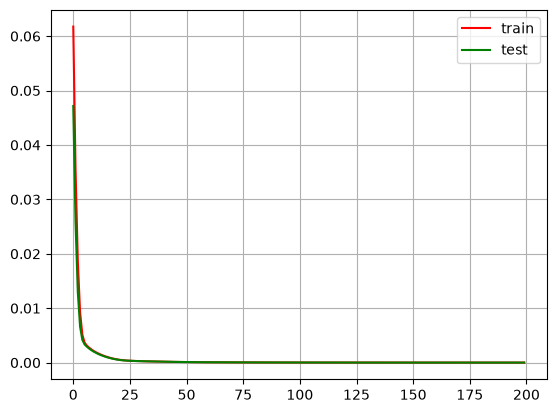

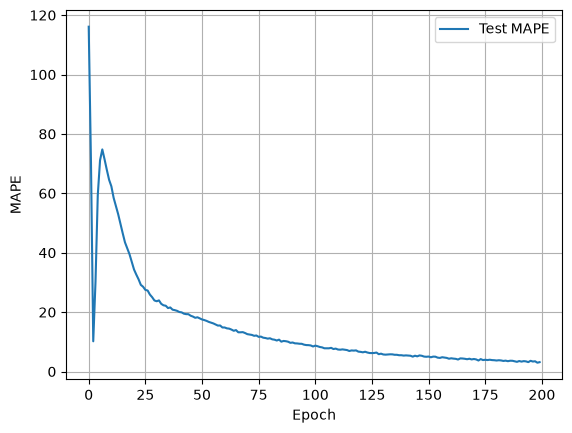

In [9]:
model = MLP()
batch_size = 512
n_epoch = 200
lr = 0.001

# Defines a optimizer to update the parameters
optimizer = optim.Adam(model.parameters(), lr=lr)
model_loss = nn.MSELoss()

train_errors, test_errors, test_mapes = run(model, model_loss, optimizer, x_train, y_train, x_val, y_val, n_epoch, batch_size)

print(f"MSE: {test_errors[-1][1]}, MAPE: {test_mapes[-1][1]}")

plt.figure("Errors")
train_errors = np.array(train_errors)
test_errors = np.array(test_errors)
plt.plot(train_errors[:,0],train_errors[:,1],"r-",label = "train")
plt.plot(test_errors[:,0],test_errors[:,1],"g-",label = "test")
plt.legend()
plt.grid()
plt.show()

test_mapes = np.array(test_mapes)
plt.plot(test_mapes[:,0], test_mapes[:,1], label="Test MAPE")
plt.xlabel("Epoch")
plt.ylabel("MAPE")
plt.legend()
plt.grid()
plt.show()

Реализация сэмплирования пакетов с помощью распределения весов на более мелкие x

- batch=128
- epoch=200
- Adam (lr=0.001)
- без изменения lr

MSE: 4.178672043053666e-06, MAPE: 2.0035321712493896


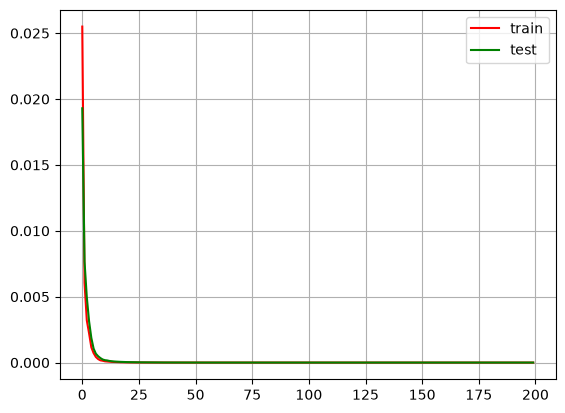

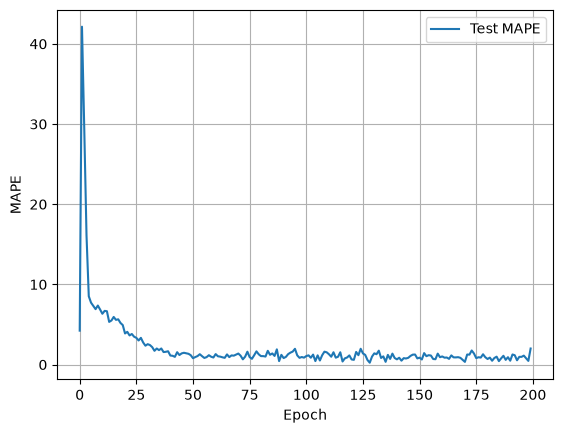

In [10]:
model = MLP()
batch_size = 128
n_epoch = 200
lr = 0.001

# Defines a optimizer to update the parameters
optimizer = optim.Adam(model.parameters(), lr=lr)
model_loss = nn.MSELoss()

train_errors, test_errors, test_mapes = run(model, model_loss, optimizer, x_train, y_train, x_val, y_val, n_epoch, batch_size, sampling=True)

print(f"MSE: {test_errors[-1][1]}, MAPE: {test_mapes[-1][1]}")

plt.figure("Errors")
train_errors = np.array(train_errors)
test_errors = np.array(test_errors)
plt.plot(train_errors[:,0],train_errors[:,1],"r-",label = "train")
plt.plot(test_errors[:,0],test_errors[:,1],"g-",label = "test")
plt.legend()
plt.grid()
plt.show()

test_mapes = np.array(test_mapes)
plt.plot(test_mapes[:,0], test_mapes[:,1], label="Test MAPE")
plt.xlabel("Epoch")
plt.ylabel("MAPE")
plt.legend()
plt.grid()
plt.show()

- Изменение LR
- Cэмплированиепакетов
- batch=128
- epoch=400
- Adam (начальный lr=0.001)

MSE: 2.2839025405119173e-05, MAPE: 3.802746057510376


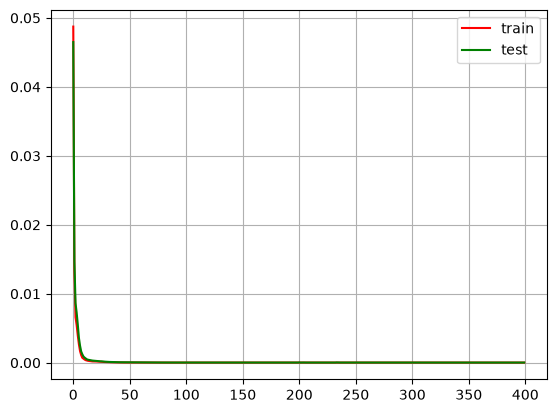

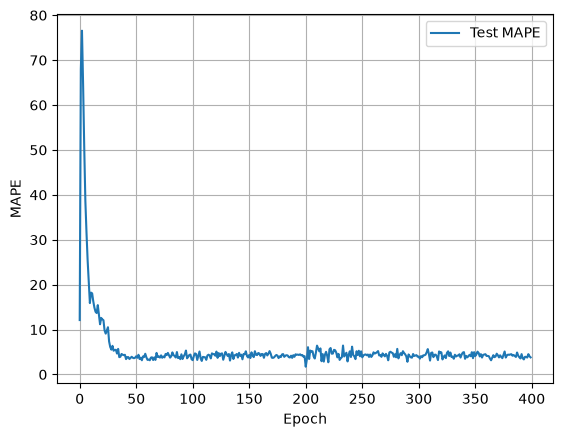

In [11]:
model = MLP()
batch_size = 128
n_epoch = 400
lr = 0.001

# Defines a optimizer to update the parameters
optimizer = optim.Adam(model.parameters(), lr=lr)
scheduler = optim.lr_scheduler.LambdaLR(
    optimizer,
    lr_lambda=lambda epoch: math.exp(-0.01 * (epoch % 200)),
)
model_loss = nn.MSELoss()

train_errors, test_errors, test_mapes = run(model, model_loss, optimizer, x_train, y_train, x_val, y_val, n_epoch, batch_size, sampling=True, scheduler=scheduler)

print(f"MSE: {test_errors[-1][1]}, MAPE: {test_mapes[-1][1]}")

plt.figure("Errors")
train_errors = np.array(train_errors)
test_errors = np.array(test_errors)
plt.plot(train_errors[:,0],train_errors[:,1],"r-",label = "train")
plt.plot(test_errors[:,0],test_errors[:,1],"g-",label = "test")
plt.legend()
plt.grid()
plt.show()

test_mapes = np.array(test_mapes)
plt.plot(test_mapes[:,0], test_mapes[:,1], label="Test MAPE")
plt.xlabel("Epoch")
plt.ylabel("MAPE")
plt.legend()
plt.grid()
plt.show()

In [12]:
model = MLP3()
batch_size = 128
n_epoch = 400
lr = 0.001

# Defines a optimizer to update the parameters
optimizer = optim.Adam(model.parameters(), lr=lr)
scheduler = optim.lr_scheduler.LambdaLR(
    optimizer,
    lr_lambda=lambda epoch: math.exp(-0.01 * (epoch % 200)),
)
model_loss = nn.MSELoss()

train_errors, test_errors, test_mapes = run(model, model_loss, optimizer, x_train, y_train, x_val, y_val, n_epoch, batch_size, sampling=True,scheduler=scheduler)

print(f"MSE: {test_errors[-1][1]}, MAPE: {test_mapes[-1][1]}")

plt.figure("Errors")
train_errors = np.array(train_errors)
test_errors = np.array(test_errors)
plt.plot(train_errors[:,0],train_errors[:,1],"r-",label = "train")
plt.plot(test_errors[:,0],test_errors[:,1],"g-",label = "test")
plt.legend()
plt.grid()
plt.show()

test_mapes = np.array(test_mapes)
plt.plot(test_mapes[:,0], test_mapes[:,1], label="Test MAPE")
plt.xlabel("Epoch")
plt.ylabel("MAPE")
plt.legend()
plt.grid()
plt.show()

KeyboardInterrupt: 

Восстановив код для примеров из презентации приступлю к пробам разных архитектур НС в том числе фукнции активации, затем можно сравнить функции потерь, а также использовать различные оптимизаторы.

In [ ]:
lr = 0.001
epochs = 200
batch_sizes = [32, 64, 128, 256, 512]

Решил, что можно просто прогнать все комбинации

In [ ]:
funcs = [nn.ReLU, nn.Sigmoid, nn.Tanh, nn.ELU, nn.LeakyReLU, nn.SiLU, nn.Mish]
model_losses = [nn.MSELoss(), nn.L1Loss()]
optimizers = {
    "Momentum": lambda params: optim.SGD(params, lr=lr, momentum=0.9),
    "Nesterov": lambda params: optim.SGD(params, lr=lr, momentum=0.9, nesterov=True),
    "Adagrad": lambda params: optim.Adagrad(params, lr=lr),
    "RMSprop": lambda params: optim.RMSprop(params, lr=lr),
    "Adadelta": lambda params: optim.Adadelta(params, lr=lr),
    "Adam": lambda params: optim.Adam(params, lr=lr),
}

Понял, что нужно сохранять результаты, чтобы не перегонять комбинации

Получается слишком много комбинаций, попробовал перенести на gpu вычисления, но выйграш отсутствовал. Принято решение распараллелить прогон конфигураций на процессоре.

In [15]:
lr = 0.001
epochs = 200
batch_sizes = [32, 64, 128, 256, 512]

funcs = [nn.ReLU, nn.Sigmoid, nn.Tanh, nn.ELU, nn.LeakyReLU, nn.SiLU, nn.Mish]
model_losses = [nn.MSELoss(), nn.L1Loss()]
optimizers = {
    "Momentum": lambda params: optim.SGD(params, lr=lr, momentum=0.9),
    "Nesterov": lambda params: optim.SGD(params, lr=lr, momentum=0.9, nesterov=True),
    "Adagrad": lambda params: optim.Adagrad(params, lr=lr),
    "RMSprop": lambda params: optim.RMSprop(params, lr=lr),
    "Adadelta": lambda params: optim.Adadelta(params, lr=lr),
    "Adam": lambda params: optim.Adam(params, lr=lr),
}

# Двуслойные модель
from itertools import product
from data import Store

store = Store("results.csv")

for layers, func, loss, (optimizer_class, optimizer_func), batch_size in product(
    range(10, 200, 10), funcs, model_losses, optimizers.items(), batch_sizes
):
    model_params = {"input_size": 1, "one": layers, "out": 1}
    run_config = {
        "model_params": str(model_params),
        "model_loss": loss.__class__.__name__,
        "func": func.__name__,
        "optimizer_class": optimizer_class,
        "epochs": epochs,
        "batch_size": batch_size,
    }
    if store.exists(run_config):
        continue
    model = MLP(**model_params, func=func)
    optimizer = optimizer_func(model.parameters())
    scheduler = optim.lr_scheduler.LambdaLR(
        optimizer,
        lr_lambda=lambda epoch: math.exp(-0.01 * (epoch % epochs)),
    )
    train_errors, test_errors, test_mapes = run(
        model,
        loss,
        optimizer,
        x_train,
        y_train,
        x_val,
        y_val,
        epochs,
        batch_size=batch_size,
        sampling=True,
        scheduler=scheduler,
    )
    print(
        f"Model: {model_params}, Func: {func.__name__}, Loss: {loss}, Optimizer: {optimizer_class}, Batch size: {batch_size}, MSE: {test_errors[-1][1]}, MAPE: {test_mapes[-1][1]}"
    )
    store.save(run_config, {"mse": test_errors[-1][1], "mape": test_mapes[-1][1]})

Model: {'input_size': 1, 'one': 20, 'out': 1}, Func: ELU, Loss: L1Loss(), Optimizer: RMSprop, Batch size: 32, MSE: 0.0026319618336856365, MAPE: 1.8617465496063232


KeyboardInterrupt: 